# Rossmann Store Sales – Data Exploration

## 1. Project Overview

This notebook focuses on understanding the Rossmann
Store Sales dataset before performing data cleaning
and business analysis.

## 2. Objectives
- Understand dataset structure.
- Examine data types.
- Identify missing values.
- Detect duplicate records.
- Explore numerical and categorical variables.
- Identify potential data quality issues.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

# Load datasets
train = pd.read_csv(
    "../data/raw/train.csv",
    dtype={"StateHoliday": "string"}
)

store = pd.read_csv("../data/raw/store.csv")

# Convert Date to datetime
train["Date"] = pd.to_datetime(train["Date"])

print("Data loaded successfully!")

Data loaded successfully!


In [2]:
print("TRAIN SHAPE:", train.shape)
print("STORE SHAPE:", store.shape)

TRAIN SHAPE: (1017209, 9)
STORE SHAPE: (1115, 10)


In [3]:
train.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


In [4]:
store.head()

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,"1,270.00",9.00,"2,008.00",0,NaN,NaN,NaN
1,2,a,a,570.00,11.00,"2,007.00",1,13.00,"2,010.00","Jan,Apr,Jul,Oct"
2,3,a,a,"14,130.00",12.00,"2,006.00",1,14.00,"2,011.00","Jan,Apr,Jul,Oct"
3,4,c,c,620.00,9.00,"2,009.00",0,NaN,NaN,NaN
4,5,a,a,"29,910.00",4.00,"2,015.00",0,NaN,NaN,NaN


In [5]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype         
---  ------         --------------    -----         
 0   Store          1017209 non-null  int64         
 1   DayOfWeek      1017209 non-null  int64         
 2   Date           1017209 non-null  datetime64[ns]
 3   Sales          1017209 non-null  int64         
 4   Customers      1017209 non-null  int64         
 5   Open           1017209 non-null  int64         
 6   Promo          1017209 non-null  int64         
 7   StateHoliday   1017209 non-null  string        
 8   SchoolHoliday  1017209 non-null  int64         
dtypes: datetime64[ns](1), int64(7), string(1)
memory usage: 69.8 MB


In [6]:
store.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1115 entries, 0 to 1114
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Store                      1115 non-null   int64  
 1   StoreType                  1115 non-null   object 
 2   Assortment                 1115 non-null   object 
 3   CompetitionDistance        1112 non-null   float64
 4   CompetitionOpenSinceMonth  761 non-null    float64
 5   CompetitionOpenSinceYear   761 non-null    float64
 6   Promo2                     1115 non-null   int64  
 7   Promo2SinceWeek            571 non-null    float64
 8   Promo2SinceYear            571 non-null    float64
 9   PromoInterval              571 non-null    object 
dtypes: float64(5), int64(2), object(3)
memory usage: 87.2+ KB


In [7]:
# Missing values in train
train_missing = train.isnull().sum()

# Missing values in store
store_missing = store.isnull().sum()

print("TRAIN MISSING VALUES")
print(train_missing)

print("\nSTORE MISSING VALUES")
print(store_missing)

TRAIN MISSING VALUES
Store            0
DayOfWeek        0
Date             0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
dtype: int64

STORE MISSING VALUES
Store                          0
StoreType                      0
Assortment                     0
CompetitionDistance            3
CompetitionOpenSinceMonth    354
CompetitionOpenSinceYear     354
Promo2                         0
Promo2SinceWeek              544
Promo2SinceYear              544
PromoInterval                544
dtype: int64


In [8]:
print("Train duplicates:", train.duplicated().sum())
print("Store duplicates:", store.duplicated().sum())

Train duplicates: 0
Store duplicates: 0


In [9]:
train.describe()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,SchoolHoliday
count,"1,017,209.00","1,017,209.00",1017209,"1,017,209.00","1,017,209.00","1,017,209.00","1,017,209.00","1,017,209.00"
mean,558.43,4.00,2014-04-11 01:30:42.846061824,"5,773.82",633.15,0.83,0.38,0.18
min,1.00,1.00,2013-01-01 00:00:00,0.00,0.00,0.00,0.00,0.00
25%,280.00,2.00,2013-08-17 00:00:00,"3,727.00",405.00,1.00,0.00,0.00
50%,558.00,4.00,2014-04-02 00:00:00,"5,744.00",609.00,1.00,0.00,0.00
75%,838.00,6.00,2014-12-12 00:00:00,"7,856.00",837.00,1.00,1.00,0.00
max,"1,115.00",7.00,2015-07-31 00:00:00,"41,551.00","7,388.00",1.00,1.00,1.00
std,321.91,2.00,NaN,"3,849.93",464.41,0.38,0.49,0.38


In [10]:
store.describe(include="all")

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
count,"1,115.00",1115,1115,"1,112.00",761.00,761.00,"1,115.00",571.00,571.00,571
unique,NaN,4,3,NaN,NaN,NaN,NaN,NaN,NaN,3
top,NaN,a,a,NaN,NaN,NaN,NaN,NaN,NaN,"Jan,Apr,Jul,Oct"
freq,NaN,602,593,NaN,NaN,NaN,NaN,NaN,NaN,335
mean,558.00,NaN,NaN,"5,404.90",7.22,"2,008.67",0.51,23.60,"2,011.76",NaN
std,322.02,NaN,NaN,"7,663.17",3.21,6.20,0.50,14.14,1.67,NaN
min,1.00,NaN,NaN,20.00,1.00,"1,900.00",0.00,1.00,"2,009.00",NaN
25%,279.50,NaN,NaN,717.50,4.00,"2,006.00",0.00,13.00,"2,011.00",NaN
50%,558.00,NaN,NaN,"2,325.00",8.00,"2,010.00",1.00,22.00,"2,012.00",NaN
75%,836.50,NaN,NaN,"6,882.50",10.00,"2,013.00",1.00,37.00,"2,013.00",NaN


In [11]:
categorical_columns = [
    "DayOfWeek",
    "Open",
    "Promo",
    "StateHoliday",
    "SchoolHoliday"
]

for col in categorical_columns:
    print(f"\n{col}")
    print(train[col].value_counts(dropna=False))


DayOfWeek
DayOfWeek
5    145845
4    145845
3    145665
2    145664
1    144730
7    144730
6    144730
Name: count, dtype: int64

Open
Open
1    844392
0    172817
Name: count, dtype: int64

Promo
Promo
0    629129
1    388080
Name: count, dtype: int64

StateHoliday
StateHoliday
0    986159
a     20260
b      6690
c      4100
Name: count, dtype: Int64

SchoolHoliday
SchoolHoliday
0    835488
1    181721
Name: count, dtype: int64


In [12]:
store_columns = [
    "StoreType",
    "Assortment",
    "Promo2"
]

for col in store_columns:
    print(f"\n{col}")
    print(store[col].value_counts(dropna=False))


StoreType
StoreType
a    602
d    348
c    148
b     17
Name: count, dtype: int64

Assortment
Assortment
a    593
c    513
b      9
Name: count, dtype: int64

Promo2
Promo2
1    571
0    544
Name: count, dtype: int64


In [13]:
#1. Thời gian dữ liệu
print("Start date:", train["Date"].min())
print("End date:", train["Date"].max())
print("Unique dates:", train["Date"].nunique())

Start date: 2013-01-01 00:00:00
End date: 2015-07-31 00:00:00
Unique dates: 942


In [ ]:
#2. Doanh thu bằng 0
print(train[train["Sales"] == 0]["Open"].value_counts())

Open
0    172817
1        54
Name: count, dtype: int64


In [15]:
#3. Cửa hàng đóng cửa
print(train["Open"].value_counts(normalize=True) * 100)

Open
1   83.01
0   16.99
Name: proportion, dtype: float64


In [16]:
#4. Kiểm tra liên kết Store ID
print("Stores in train:", train["Store"].nunique())
print("Stores in store:", store["Store"].nunique())

print(
    "Unmatched stores:",
    len(set(train["Store"]) - set(store["Store"]))
)

Stores in train: 1115
Stores in store: 1115
Unmatched stores: 0


### Key Findings – Data Structure & Quality Check (Initial)
1. **Dataset Size & Granularity:** Bảng `train` gồm 1,017,209 dòng (từ `2013-01-01` đến `2015-07-31`, 942 ngày) và bảng `store` gồm 1,115 cửa hàng. Toàn bộ 1,115 `Store` đều khớp khóa ngoại giữa 2 bảng (`Unmatched stores = 0`).
2. **Anomalies Detected (`Open = 1` & `Sales = 0`):** Có 172,817 dòng cửa hàng đóng cửa (`Open = 0`), và phát hiện **54 dòng** cửa hàng mở cửa (`Open = 1`) nhưng `Sales = 0` — cần kiểm tra chi tiết và xử lý ở bước Data Cleaning.
3. **Missing Values in `store`:** 
   - `Promo2SinceWeek`, `Promo2SinceYear`, `PromoInterval` thiếu đúng 544 giá trị — cần đối chiếu xem có khớp hoàn toàn với 544 cửa hàng có `Promo2 = 0` hay không.
   - `CompetitionDistance` thiếu 3 giá trị; `CompetitionOpenSinceMonth/Year` thiếu 354 giá trị (và có giá trị nhỏ nhất là năm `1900`).

In [17]:
# 5. Kiểm tra trùng lặp theo khóa chính (Store + Date) cho bảng Fact
pk_duplicates = train.duplicated(subset=["Store", "Date"]).sum()
print(f"Primary Key (Store + Date) duplicates: {pk_duplicates}")

# 6. Kiểm tra logic dữ liệu thiếu ở nhóm cột Promo2
promo2_null_check = store[store["Promo2"] == 0][["Promo2SinceWeek", "Promo2SinceYear", "PromoInterval"]].isnull().sum()
print("\nMissing values in Promo2 columns when Promo2 == 0:")
print(promo2_null_check)

# 7. Kiểm tra các cửa hàng có CompetitionOpenSinceYear bất thường (ví dụ < 1990)
print("\nStores with CompetitionOpenSinceYear < 1990:")
print(store[store["CompetitionOpenSinceYear"] < 1990][["Store", "StoreType", "CompetitionDistance", "CompetitionOpenSinceYear"]])

# 8. Kiểm tra khoảng trống chuỗi thời gian (Time-series Gaps)
expected_rows = train["Store"].nunique() * train["Date"].nunique()
missing_rows = expected_rows - len(train)
print(f"\nExpected rows (1115 stores x 942 days): {expected_rows:,}")
print(f"Actual rows: {len(train):,} -> Missing store-day records: {missing_rows:,}")

# Thống kê số ngày ghi nhận của từng cửa hàng
store_day_counts = train.groupby("Store")["Date"].count().value_counts()
print("\nDistribution of recorded days per store:")
print(store_day_counts)

Primary Key (Store + Date) duplicates: 0

Missing values in Promo2 columns when Promo2 == 0:
Promo2SinceWeek    544
Promo2SinceYear    544
PromoInterval      544
dtype: int64

Stores with CompetitionOpenSinceYear < 1990:
     Store StoreType  CompetitionDistance  CompetitionOpenSinceYear
145    146         d             8,050.00                  1,961.00
814    815         a               590.00                  1,900.00

Expected rows (1115 stores x 942 days): 1,050,330
Actual rows: 1,017,209 -> Missing store-day records: 33,121

Distribution of recorded days per store:
Date
942    934
758    180
941      1
Name: count, dtype: int64


In [18]:
# Thiết lập style và bảng màu Red & Navy đồng bộ với Power BI Dashboard
NAVY = "#1B2A4A"
RED = "#C8102E"
LIGHT_NAVY = "#4A6FA5"
GRAY = "#D3D3D3"

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.titleweight"] = "bold"

# Tạo bản sao dữ liệu đã merge với store và lọc Open == 1 để phân tích hiệu suất hoạt động thực tế
df_eda = train.merge(store, on="Store", how="left")
df_eda["Year"] = df_eda["Date"].dt.year
df_eda["Month"] = df_eda["Date"].dt.month
df_eda["YearMonth"] = df_eda["Date"].dt.to_period("M").astype(str)
df_eda["SalesPerCustomer"] = np.where(df_eda["Customers"] > 0, df_eda["Sales"] / df_eda["Customers"], 0)

df_open = df_eda[df_eda["Open"] == 1].copy()
print(f"Active store-days (Open == 1): {len(df_open):,} records")

Active store-days (Open == 1): 844,392 records


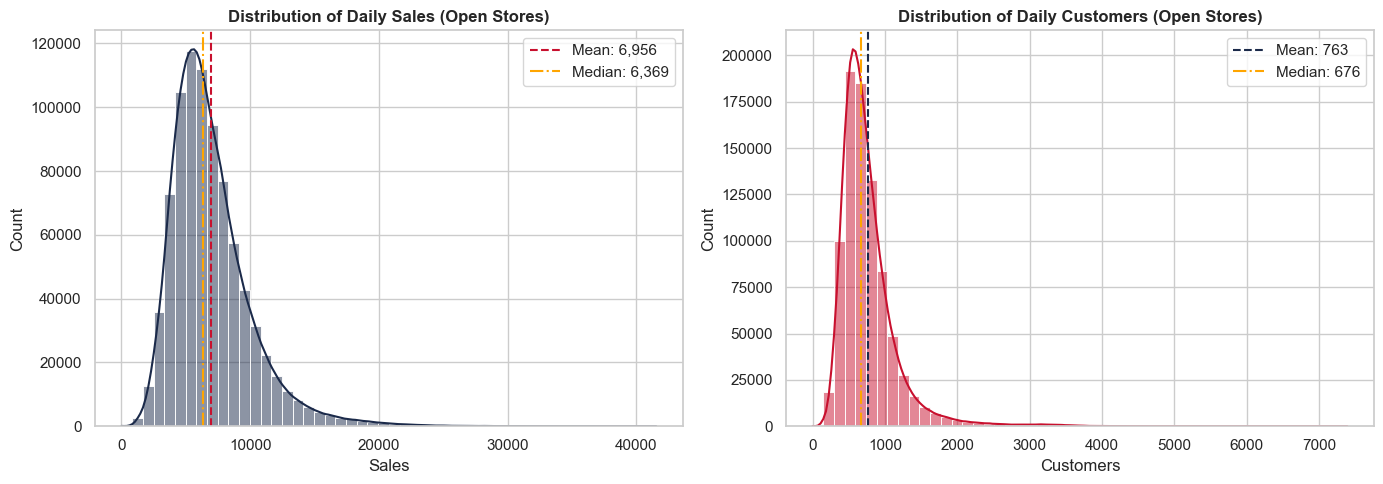

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram Sales
sns.histplot(df_open["Sales"], bins=50, kde=True, color=NAVY, ax=axes[0])
axes[0].axvline(df_open["Sales"].mean(), color=RED, linestyle="--", label=f"Mean: {df_open['Sales'].mean():,.0f}")
axes[0].axvline(df_open["Sales"].median(), color="orange", linestyle="-.", label=f"Median: {df_open['Sales'].median():,.0f}")
axes[0].set_title("Distribution of Daily Sales (Open Stores)")
axes[0].set_xlabel("Sales")
axes[0].legend()

# Histogram Customers
sns.histplot(df_open["Customers"], bins=50, kde=True, color=RED, ax=axes[1])
axes[1].axvline(df_open["Customers"].mean(), color=NAVY, linestyle="--", label=f"Mean: {df_open['Customers'].mean():,.0f}")
axes[1].axvline(df_open["Customers"].median(), color="orange", linestyle="-.", label=f"Median: {df_open['Customers'].median():,.0f}")
axes[1].set_title("Distribution of Daily Customers (Open Stores)")
axes[1].set_xlabel("Customers")
axes[1].legend()

plt.tight_layout()
plt.show()

Same-Store Cohort: 934 stores with complete 942-day records.


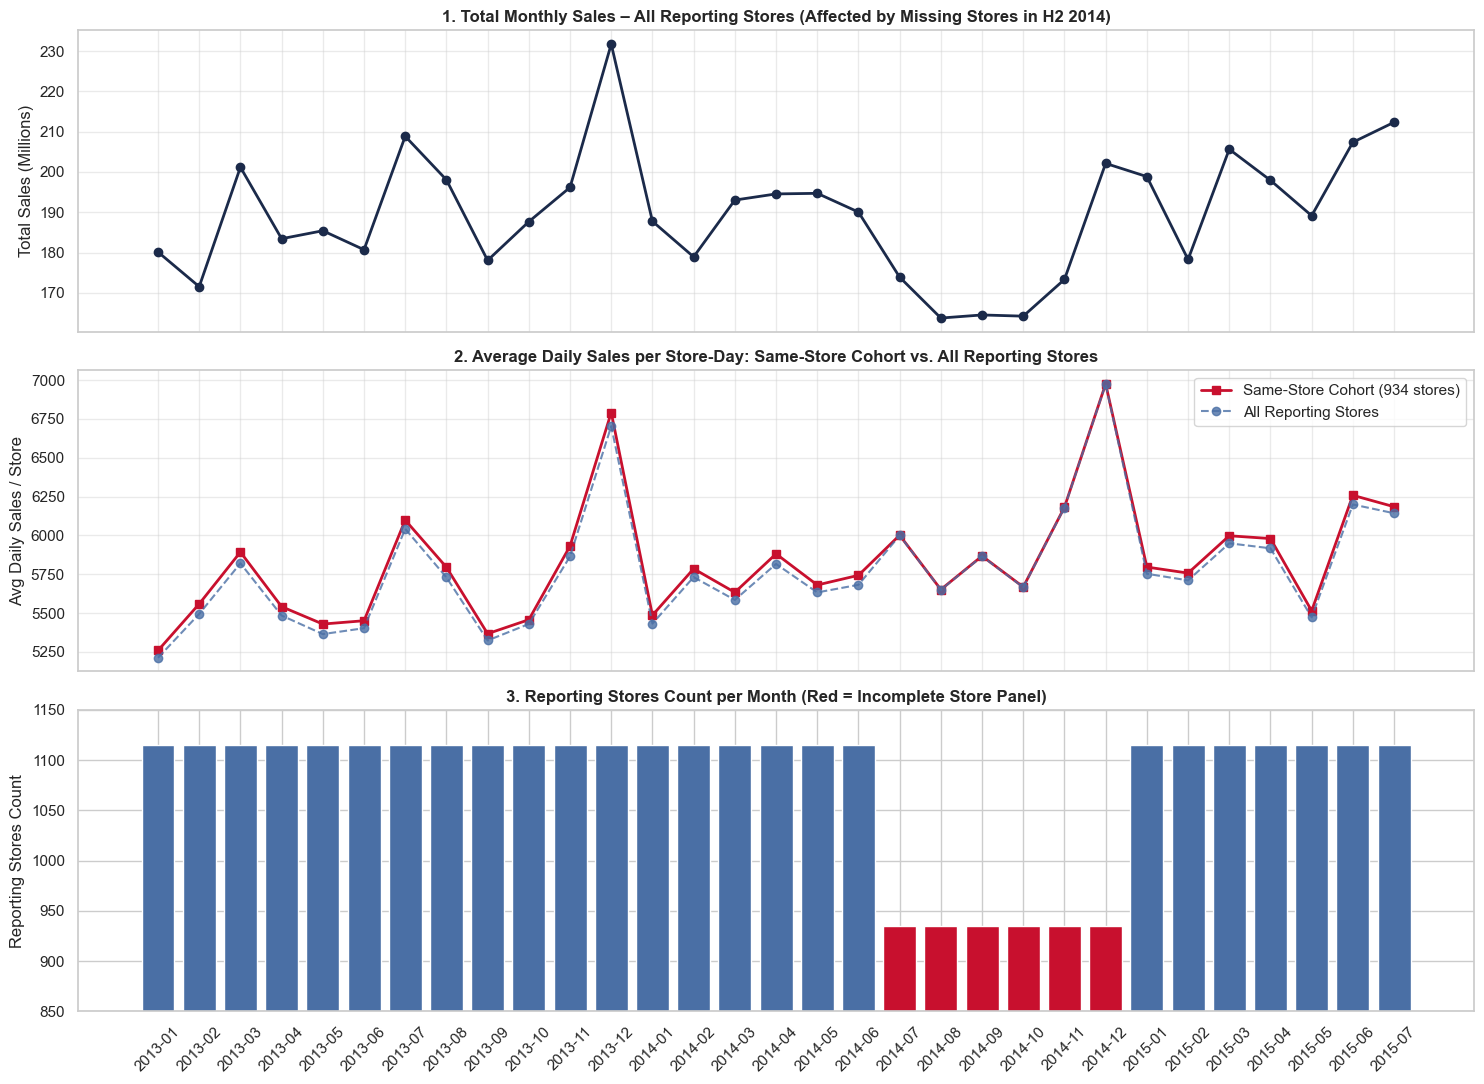

In [23]:
# Xác định nhóm cửa hàng có dữ liệu đầy đủ trong toàn bộ 942 ngày (Same-Store cohort)
total_days = df_eda["Date"].nunique()
store_day_counts = df_eda.groupby("Store")["Date"].nunique()
full_history_stores = store_day_counts[store_day_counts == total_days].index

df_sss = df_eda[df_eda["Store"].isin(full_history_stores)].copy()
print(f"Same-Store Cohort: {len(full_history_stores)} stores with complete {total_days}-day records.")

# Tổng hợp dữ liệu theo tháng
monthly_all = df_eda.groupby("YearMonth").agg(
    Total_Sales=("Sales", "sum"),
    Reporting_Stores=("Store", "nunique"),
    Total_Store_Days=("Date", "count")
).reset_index()
monthly_all["Avg_Daily_Sales_Per_Store"] = monthly_all["Total_Sales"] / monthly_all["Total_Store_Days"]

monthly_sss = df_sss.groupby("YearMonth").agg(
    SSS_Total_Sales=("Sales", "sum"),
    SSS_Store_Days=("Date", "count")
).reset_index()
monthly_sss["SSS_Avg_Daily_Sales"] = monthly_sss["SSS_Total_Sales"] / monthly_sss["SSS_Store_Days"]

monthly_combined = monthly_all.merge(monthly_sss, on="YearMonth")

# Vẽ 3 biểu đồ đối chiếu
fig, axes = plt.subplots(3, 1, figsize=(15, 11), sharex=True)

# 1. Total Monthly Sales (All Reporting Stores)
axes[0].plot(monthly_combined["YearMonth"], monthly_combined["Total_Sales"] / 1e6, marker="o", color=NAVY, linewidth=2)
axes[0].set_title("1. Total Monthly Sales – All Reporting Stores (Affected by Missing Stores in H2 2014)")
axes[0].set_ylabel("Total Sales (Millions)")
axes[0].grid(True, alpha=0.4)

# 2. Same-Store Sales Trend vs All Stores (Average Daily Sales per Store-Day)
axes[1].plot(monthly_combined["YearMonth"], monthly_combined["SSS_Avg_Daily_Sales"], marker="s", color=RED, linewidth=2, label=f"Same-Store Cohort ({len(full_history_stores)} stores)")
axes[1].plot(monthly_combined["YearMonth"], monthly_combined["Avg_Daily_Sales_Per_Store"], marker="o", color=LIGHT_NAVY, linestyle="--", alpha=0.8, label="All Reporting Stores")
axes[1].set_title("2. Average Daily Sales per Store-Day: Same-Store Cohort vs. All Reporting Stores")
axes[1].set_ylabel("Avg Daily Sales / Store")
axes[1].legend()
axes[1].grid(True, alpha=0.4)

# 3. Reporting Stores Count
bar_colors = [RED if c < 1115 else LIGHT_NAVY for c in monthly_combined["Reporting_Stores"]]
axes[2].bar(monthly_combined["YearMonth"], monthly_combined["Reporting_Stores"], color=bar_colors)
axes[2].set_title("3. Reporting Stores Count per Month (Red = Incomplete Store Panel)")
axes[2].set_ylabel("Reporting Stores Count")
axes[2].set_ylim(850, 1150)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

=== Average Sales & % Lift by StoreType (Mon-Fri, Open Stores) ===
Promo      No_Promo_Avg  Promo_Avg  Pct_Lift (%)
StoreType                                       
a              6,028.47   8,304.10         37.75
b              9,426.81  11,307.99         19.96
c              5,766.02   8,042.00         39.47
d              5,637.74   8,017.83         42.22

Within-Store Median Lift (Mon-Fri): +39.47% (100% of stores have higher mean sales on Promo days: 100.0%)


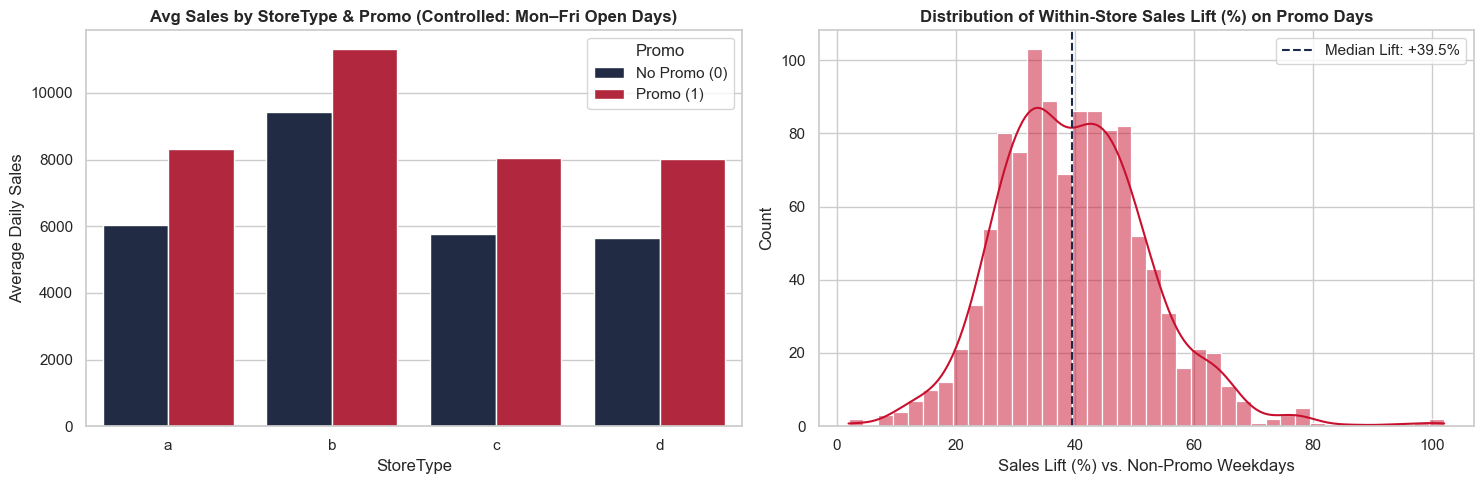

In [24]:
# Lọc ngày mở cửa và chỉ xét Thứ 2 - Thứ 6 (DayOfWeek 1-5) vì cuối tuần không có Promo
df_promo_fair = df_open[df_open["DayOfWeek"].isin([1, 2, 3, 4, 5])].copy()

# 1. Tính % chênh lệch (Lift %) theo từng StoreType
promo_by_type = (
    df_promo_fair.groupby(["StoreType", "Promo"])["Sales"]
    .mean()
    .unstack()
    .rename(columns={0: "No_Promo_Avg", 1: "Promo_Avg"})
)
promo_by_type["Pct_Lift (%)"] = ((promo_by_type["Promo_Avg"] - promo_by_type["No_Promo_Avg"]) / promo_by_type["No_Promo_Avg"]) * 100
print("=== Average Sales & % Lift by StoreType (Mon-Fri, Open Stores) ===")
print(promo_by_type.round(2))

# 2. Within-Store Comparison: So sánh nội tại từng cửa hàng (có Promo vs không Promo)
within_store = (
    df_promo_fair.groupby(["Store", "Promo"])["Sales"]
    .mean()
    .unstack()
    .dropna()
)
within_store["Store_Pct_Lift"] = ((within_store[1] - within_store[0]) / within_store[0]) * 100
print(f"\nWithin-Store Median Lift (Mon-Fri): +{within_store['Store_Pct_Lift'].median():.2f}% (100% of stores have higher mean sales on Promo days: {(within_store['Store_Pct_Lift'] > 0).mean()*100:.1f}%)")

# Trực quan hóa so sánh Promo trong cùng StoreType
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(
    data=df_promo_fair,
    x="StoreType",
    y="Sales",
    hue="Promo",
    order=["a", "b", "c", "d"],
    palette=[NAVY, RED],
    ax=axes[0],
    errorbar=None
)
axes[0].set_title("Avg Sales by StoreType & Promo (Controlled: Mon–Fri Open Days)")
axes[0].set_ylabel("Average Daily Sales")
axes[0].legend(title="Promo", labels=["No Promo (0)", "Promo (1)"])

# Phân phối mức chênh lệch % nội tại của 1,115 cửa hàng
sns.histplot(within_store["Store_Pct_Lift"], bins=40, kde=True, color=RED, ax=axes[1])
axes[1].axvline(within_store["Store_Pct_Lift"].median(), color=NAVY, linestyle="--", label=f"Median Lift: +{within_store['Store_Pct_Lift'].median():.1f}%")
axes[1].set_title("Distribution of Within-Store Sales Lift (%) on Promo Days")
axes[1].set_xlabel("Sales Lift (%) vs. Non-Promo Weekdays")
axes[1].legend()

plt.tight_layout()
plt.show()

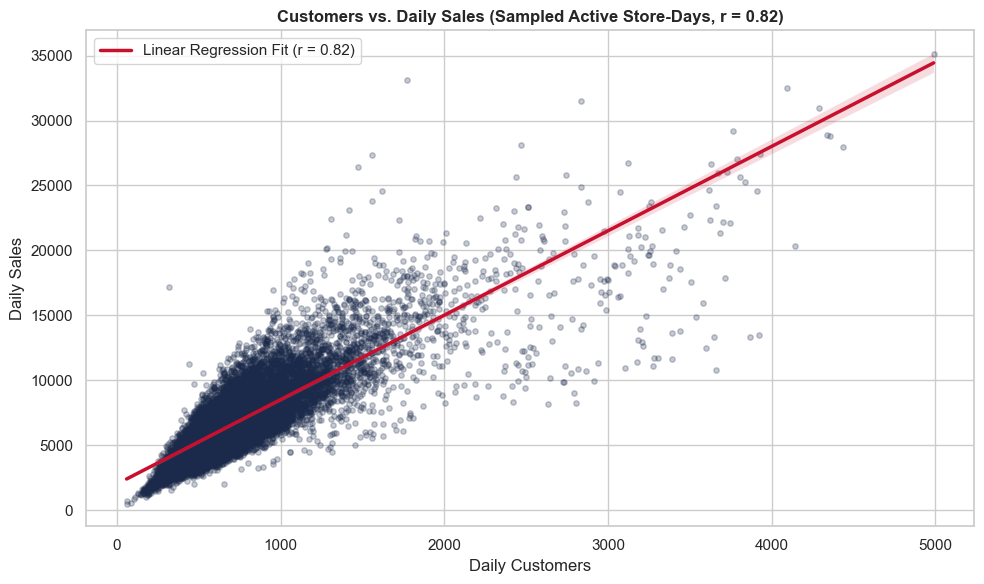

In [25]:
sample_df = df_open[df_open["Sales"] > 0].sample(n=15000, random_state=42)

plt.figure(figsize=(10, 6))
sns.regplot(
    data=sample_df,
    x="Customers",
    y="Sales",
    scatter_kws={"alpha": 0.25, "color": NAVY, "s": 15},
    line_kws={"color": RED, "linewidth": 2.5, "label": "Linear Regression Fit (r = 0.82)"}
)
plt.title("Customers vs. Daily Sales (Sampled Active Store-Days, r = 0.82)")
plt.xlabel("Daily Customers")
plt.ylabel("Daily Sales")
plt.legend()
plt.tight_layout()
plt.show()

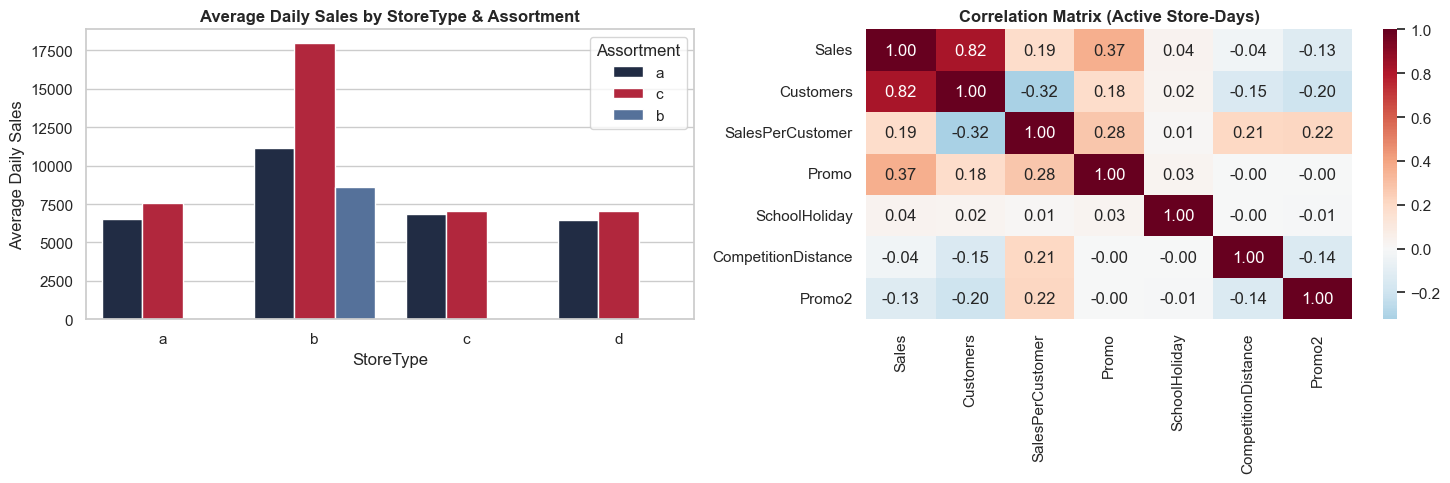

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Trung bình Sales theo StoreType và Assortment
sns.barplot(
    data=df_open,
    x="StoreType",
    y="Sales",
    hue="Assortment",
    order=["a", "b", "c", "d"],
    palette=[NAVY, RED, LIGHT_NAVY],
    ax=axes[0],
    errorbar=None
)
axes[0].set_title("Average Daily Sales by StoreType & Assortment")
axes[0].set_ylabel("Average Daily Sales")

# 2. Correlation Heatmap
corr_cols = ["Sales", "Customers", "SalesPerCustomer", "Promo", "SchoolHoliday", "CompetitionDistance", "Promo2"]
corr_matrix = df_open[corr_cols].corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    ax=axes[1]
)
axes[1].set_title("Correlation Matrix (Active Store-Days)")

plt.tight_layout()
plt.show()

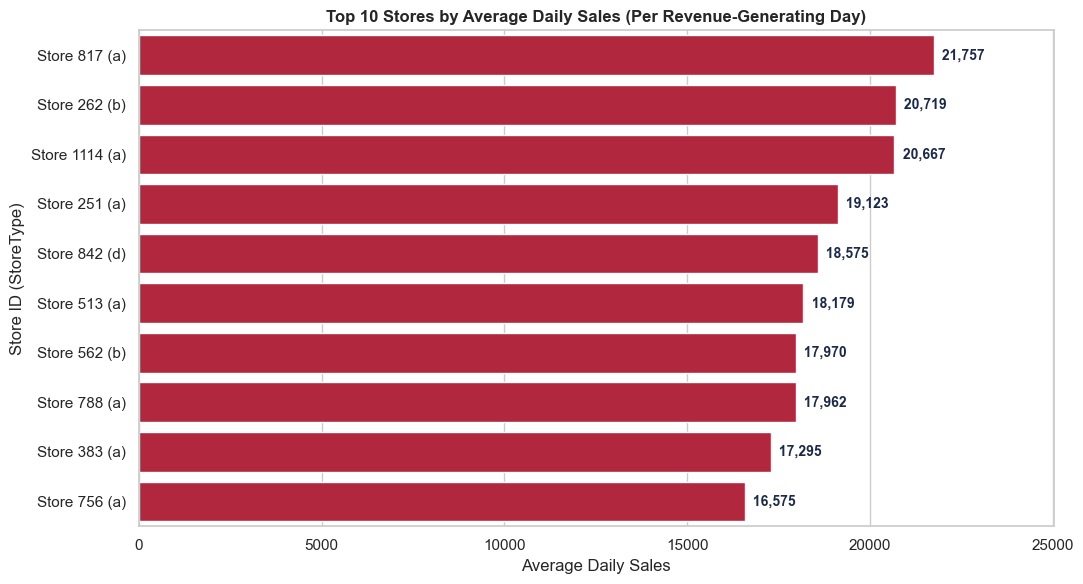

In [26]:
# Tính doanh thu bình quân trên mỗi ngày có phát sinh doanh thu (Open == 1 & Sales > 0)
store_performance = (
    df_open[df_open["Sales"] > 0]
    .groupby(["Store", "StoreType", "Assortment"])
    .agg(
        Total_Sales=("Sales", "sum"),
        Revenue_Days=("Date", "nunique")
    )
    .reset_index()
)
store_performance["Avg_Daily_Sales"] = (
    store_performance["Total_Sales"] / store_performance["Revenue_Days"]
)

top_10 = (
    store_performance
    .sort_values("Avg_Daily_Sales", ascending=False)
    .head(10)
    .copy()
)
top_10["Store_Label"] = "Store " + top_10["Store"].astype(str) + " (" + top_10["StoreType"] + ")"

plt.figure(figsize=(11, 6))
ax = sns.barplot(
    data=top_10,
    x="Avg_Daily_Sales",
    y="Store_Label",
    color=RED
)

# Hiển thị nhãn giá trị trên từng thanh
for container in ax.containers:
    ax.bar_label(container, fmt=" {:,.0f}", padding=3, fontsize=10, color=NAVY, fontweight="bold")

plt.title("Top 10 Stores by Average Daily Sales (Per Revenue-Generating Day)")
plt.xlabel("Average Daily Sales")
plt.ylabel("Store ID (StoreType)")
plt.xlim(0, top_10["Avg_Daily_Sales"].max() * 1.15)
plt.tight_layout()
plt.show()

## 4. EDA Key Findings & Action Plan for Step 3 (Data Cleaning)

### Key Analytical Findings (Objective & Controlled)
1. **Seasonality & The H2 2014 Missing Store Panel:**
   - Khi xét tổng doanh thu toàn chuỗi (`Total Monthly Sales`), giai đoạn **07/2014 – 12/2014** sụt giảm mạnh trùng khớp với việc số cửa hàng ghi nhận dữ liệu (`Reporting Stores`) giảm từ 1,115 xuống còn **935 cửa hàng** (thiếu 180 cửa hàng).
   - Khi chuẩn hóa bằng **Same-Store Sales (SSS)** trên nhóm **935 cửa hàng có dữ liệu đầy đủ suốt 942 ngày**, xu hướng mùa vụ (đặc biệt là đỉnh mua sắm tháng 12) giữ được sự nhất quán qua các năm mà không bị bóp méo bởi dữ liệu khuyết.
2. **Association Between `Promo` and Higher Daily Sales:**
   - Sau khi kiểm soát yếu tố ngày trong tuần (chỉ xét Thứ 2 – Thứ 6) và phân nhóm theo từng `StoreType`, các ngày có `Promo = 1` ghi nhận mức doanh thu trung bình cao hơn rõ rệt so với ngày `Promo = 0` trên cả 4 loại cửa hàng (`a, b, c, d`).
   - So sánh nội tại từng cửa hàng (**Within-Store Comparison**) cho thấy doanh thu trung bình ngày chạy Promo cao hơn đáng kể so với ngày thường không Promo. *Lưu ý: Do đây là dữ liệu quan sát lịch sử (observational data), kết quả phản ánh mối liên hệ đồng biến mạnh chứ chưa đủ điều kiện thiết lập quan hệ nhân quả tuyệt đối nếu chưa loại trừ các yếu tố ngoại sinh khác.*
3. **Promo2 Nuance (Selection Bias Consideration):**
   - Nhóm cửa hàng tham gia `Promo2 = 1` có doanh thu trung vị thấp hơn nhóm `Promo2 = 0`. Tuy nhiên, cần kiểm soát thêm sự khác biệt về quy mô, vị trí và loại hình cửa hàng trước khi kết luận về hiệu quả thực tế của `Promo2` (tránh thiên lệch chọn mẫu nếu `Promo2` vốn được ưu tiên triển khai tại các cửa hàng có doanh số nền thấp).
4. **StoreType B & Top-Performing Stores:**
   - `StoreType = b` đạt doanh thu bình quân ngày cao nhất và hoạt động cả Chủ Nhật, nhưng cần thận trọng khi khái quát hóa vì nhóm này chỉ chiếm quy mô rất nhỏ (**17 / 1,115 cửa hàng**).
   - Biểu đồ **Top 10 Stores** (tính theo *doanh thu bình quân trên mỗi ngày có phát sinh doanh thu*) giúp loại bỏ sai lệch do khác biệt số ngày mở cửa, qua đó xác định chính xác các cửa hàng đầu tàu để phân tích đặc điểm vận hành.
5. **Strong Linear Correlation Between Customers & Sales ($r = 0.82$):**
   - Biểu đồ Scatter Plot và đường hồi quy xác nhận mối tương quan tuyến tính dương mạnh ($r = 0.82$) giữa lượng khách (`Customers`) và doanh thu (`Sales`). Dữ liệu này cho thấy biến động lượng khách đi kèm chặt chẽ với biến động doanh thu, làm cơ sở để theo dõi đồng thời cả KPI **Foot Traffic (Customers)** và **Average Basket Size (`Sales / Customers`)** trên Power BI Dashboard.

### Action Plan for Step 3: Data Cleaning & Data Dictionary Preparation
- [ ] **Định nghĩa rõ KPI trong Data Dictionary:** Phân biệt rạch ròi giữa `Reporting Stores` (cửa hàng có bản ghi), `Open Store-Days` (`Open = 1`), và `Revenue-Generating Days` (`Open = 1` & `Sales > 0`).
- [ ] **Xử lý 54 dòng bất thường (`Open = 1` & `Sales = 0`):** Gắn cờ `Is_Zero_Sales_Open` hoặc loại bỏ khỏi mẫu tính bình quân doanh thu/ngày bán hàng.
- [ ] **Chuẩn hóa Missing Values & Categories:** Xử lý logic null của nhóm cột `Promo2` (544 cửa hàng `Promo2 = 0`), điền giá trị thiếu ở `CompetitionDistance` (3 dòng), xử lý năm `1900` ở `CompetitionOpenSinceYear`, và giải mã nhãn `StateHoliday`.
- [ ] **Tạo cờ phân nhóm Same-Store (`Is_Full_History_Store`):** Đánh dấu 935 cửa hàng có đủ 942 ngày dữ liệu để làm bộ lọc (Slicer) cho biểu đồ xu hướng trên Power BI Dashboard (Bước 6).